In [1]:
import sqlite3
import pandas as pd

# Connect to the database we built on Day 1
conn = sqlite3.connect("olist.db")

query = """
SELECT o.order_id,
       c.customer_unique_id,
       o.order_purchase_timestamp
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
"""

orders = pd.read_sql(query, conn, parse_dates=["order_purchase_timestamp"])

print("Rows:", len(orders))
print("Unique customers:", orders["customer_unique_id"].nunique())
orders.head()

Rows: 96211
Unique customers: 93104


,order_id,customer_unique_id,order_purchase_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39


In [2]:
# Number of orders each real customer placed
orders_per_customer = orders.groupby("customer_unique_id")["order_id"].nunique()

total_customers = len(orders_per_customer)
repeat_customers = (orders_per_customer > 1).sum()
repeat_rate = 100 * repeat_customers / total_customers

print("Total customers:", total_customers)
print("Repeat customers (2+ orders):", repeat_customers)
print("Repeat rate: {:.2f}%".format(repeat_rate))
print("One-time customers: {:.2f}%".format(100 - repeat_rate))
print()
print("How many customers placed N orders:")
print(orders_per_customer.value_counts().sort_index())

Total customers: 93104
Repeat customers (2+ orders): 2789
Repeat rate: 3.00%
One-time customers: 97.00%

How many customers placed N orders:
order_id
1     90315
2      2562
3       180
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


In [3]:
import numpy as np

# 1. Turn each order date into a month number (e.g. Jan 2017 -> 2017*12 + 1)
ts = orders["order_purchase_timestamp"]
orders["month_num"] = ts.dt.year * 12 + ts.dt.month

# 2. Each customer's first purchase month = their cohort
orders["first_month_num"] = orders.groupby("customer_unique_id")["month_num"].transform("min")
orders["cohort"] = (orders.groupby("customer_unique_id")["order_purchase_timestamp"]
                    .transform("min").dt.strftime("%Y-%m"))

# 3. How many months after their first purchase was each order?
orders["months_since_first"] = orders["month_num"] - orders["first_month_num"]

# 4. Count unique customers per cohort and month
cohort_counts = (orders.groupby(["cohort", "months_since_first"])["customer_unique_id"]
                 .nunique()
                 .unstack(fill_value=0))

# 5. Convert counts into % of the cohort's starting size
retention = cohort_counts.divide(cohort_counts[0], axis=0) * 100

# 6. Blank out months that are after Aug 2018 (no data yet, so not a real 0%)
cohort_start = orders.groupby("cohort")["first_month_num"].min()
last_month = orders["month_num"].max()
for m in retention.columns:
    retention.loc[cohort_start + m > last_month, m] = np.nan

print("Customers in each cohort:")
print(cohort_counts[0])
print()
print("Retention % (months 1-6 after first purchase):")
print(retention.iloc[:, 1:7].round(2))
print()
print("Average retention % across cohorts:")
print(retention.iloc[:, 1:7].mean().round(2))

Customers in each cohort:
cohort
2017-01     718
2017-02    1628
2017-03    2503
2017-04    2257
2017-05    3451
2017-06    3037
2017-07    3753
2017-08    4057
2017-09    4005
2017-10    4328
2017-11    7061
2017-12    5338
2018-01    6843
2018-02    6288
2018-03    6775
2018-04    6582
2018-05    6508
2018-06    5879
2018-07    5949
2018-08    6144
Name: 0, dtype: int64

Retention % (months 1-6 after first purchase):
months_since_first     1     2     3     4     5     6
cohort                                                
2017-01             0.28  0.28  0.14  0.42  0.14  0.42
2017-02             0.18  0.31  0.12  0.43  0.12  0.25
2017-03             0.44  0.36  0.40  0.36  0.16  0.16
2017-04             0.62  0.22  0.18  0.27  0.27  0.35
2017-05             0.46  0.46  0.29  0.29  0.32  0.41
2017-06             0.49  0.40  0.43  0.30  0.40  0.36
2017-07             0.53  0.35  0.24  0.29  0.21  0.32
2017-08             0.69  0.35  0.27  0.35  0.52  0.30
2017-09             0.70  0

In [4]:
print(retention.iloc[:, 1:7].round(2).to_string())
print()
print("Average:")
print(retention.iloc[:, 1:7].mean().round(2).to_string())

months_since_first     1     2     3     4     5     6
cohort                                                
2017-01             0.28  0.28  0.14  0.42  0.14  0.42
2017-02             0.18  0.31  0.12  0.43  0.12  0.25
2017-03             0.44  0.36  0.40  0.36  0.16  0.16
2017-04             0.62  0.22  0.18  0.27  0.27  0.35
2017-05             0.46  0.46  0.29  0.29  0.32  0.41
2017-06             0.49  0.40  0.43  0.30  0.40  0.36
2017-07             0.53  0.35  0.24  0.29  0.21  0.32
2017-08             0.69  0.35  0.27  0.35  0.52  0.30
2017-09             0.70  0.55  0.27  0.45  0.22  0.22
2017-10             0.72  0.25  0.09  0.23  0.21  0.21
2017-11             0.57  0.37  0.17  0.17  0.18  0.11
2017-12             0.21  0.28  0.34  0.26  0.21  0.17
2018-01             0.34  0.37  0.29  0.29  0.16  0.18
2018-02             0.35  0.40  0.30  0.25  0.22  0.21
2018-03             0.40  0.30  0.30  0.12  0.12   NaN
2018-04             0.59  0.30  0.24  0.14   NaN   NaN
2018-05   

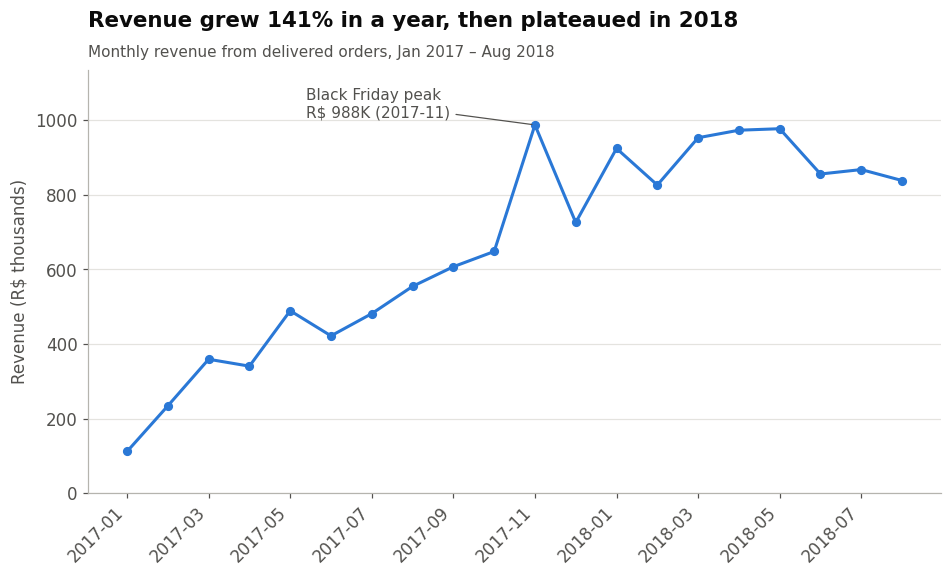

In [5]:
import os
import matplotlib.pyplot as plt

# ---------- Chart style (used by every chart) ----------
os.makedirs("charts", exist_ok=True)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left",
})

# ---------- Data: monthly revenue (same query as Day 3) ----------
monthly = pd.read_sql("""
    SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
           SUM(oi.price) AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY month
    ORDER BY month
""", conn)

# ---------- Chart 1: monthly revenue ----------
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly["month"], monthly["revenue"] / 1000,
        color=BLUE, linewidth=2, marker="o", markersize=5)

# Label only the peak month
peak = monthly.loc[monthly["revenue"].idxmax()]
ax.annotate(f"Black Friday peak\nR$ {peak['revenue']/1000:,.0f}K ({peak['month']})",
            xy=(peak["month"], peak["revenue"] / 1000), xytext=(-150, 5),
            textcoords="offset points", color=INK2, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))

ax.set_title("Revenue grew 141% in a year, then plateaued in 2018", pad=28)
ax.text(0, 1.03, "Monthly revenue from delivered orders, Jan 2017 – Aug 2018",
        transform=ax.transAxes, color=INK2, fontsize=10)
ax.set_ylabel("Revenue (R$ thousands)")
ax.set_ylim(0, monthly["revenue"].max() / 1000 * 1.15)
ax.set_xticks(range(0, len(monthly), 2))
ax.set_xticklabels(monthly["month"][::2], rotation=45, ha="right")
ax.grid(axis="x", visible=False)

fig.savefig("charts/01_monthly_revenue.png", bbox_inches="tight")
plt.show()

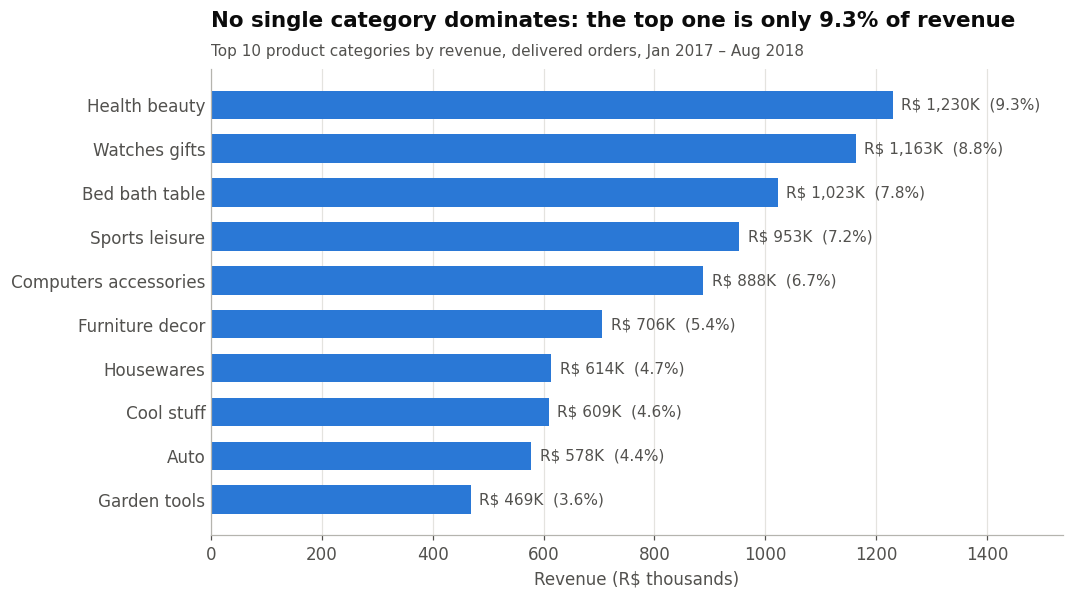

In [6]:
# ---------- Data: top 10 categories (same query as Day 3, Step 3) ----------
categories = pd.read_sql("""
    WITH category_sales AS (
        SELECT COALESCE(t.product_category_name_english,
                        p.product_category_name, 'unknown') AS category,
               SUM(oi.price) AS revenue
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN products p     ON oi.product_id = p.product_id
        LEFT JOIN category_translation t
               ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
          AND o.order_purchase_timestamp >= '2017-01-01'
          AND o.order_purchase_timestamp <  '2018-09-01'
        GROUP BY category
    )
    SELECT category,
           revenue,
           ROUND(100.0 * revenue / SUM(revenue) OVER (), 1) AS share_pct
    FROM category_sales
    ORDER BY revenue DESC
    LIMIT 10
""", conn)

# ---------- Chart 2: horizontal bar chart ----------
top = categories.iloc[::-1]   # reverse so the biggest bar is at the top
labels = top["category"].str.replace("_", " ").str.capitalize()

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(labels, top["revenue"] / 1000, color=BLUE, height=0.65)

# Value + share at the end of each bar
for bar, share in zip(bars, top["share_pct"]):
    ax.text(bar.get_width() + 15, bar.get_y() + bar.get_height() / 2,
            f"R$ {bar.get_width():,.0f}K  ({share}%)",
            va="center", color=INK2, fontsize=10)

ax.set_title("No single category dominates: the top one is only 9.3% of revenue", pad=28)
ax.text(0, 1.03, "Top 10 product categories by revenue, delivered orders, Jan 2017 – Aug 2018",
        transform=ax.transAxes, color=INK2, fontsize=10)
ax.set_xlabel("Revenue (R$ thousands)")
ax.set_xlim(0, top["revenue"].max() / 1000 * 1.25)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

fig.savefig("charts/02_top_categories.png", bbox_inches="tight")
plt.show()

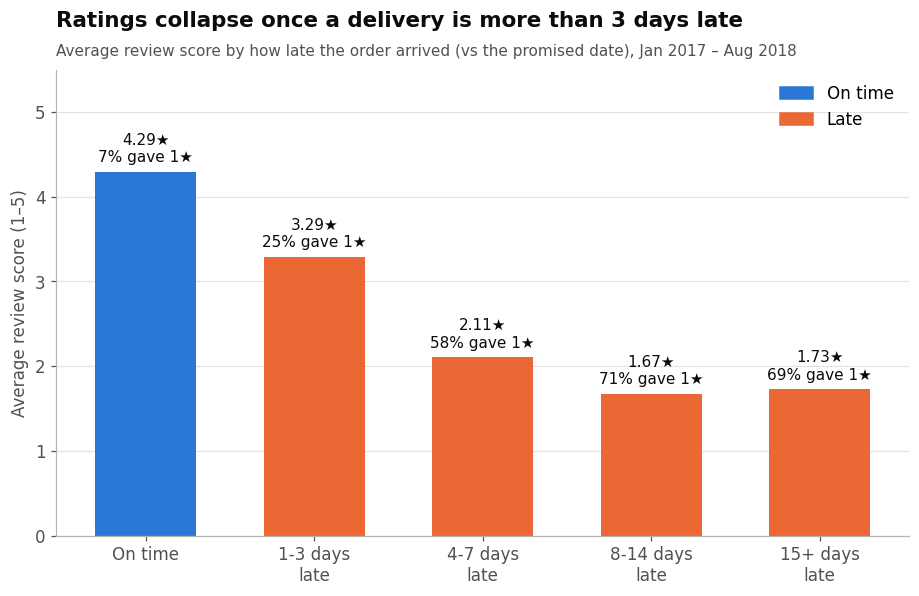

In [7]:
from matplotlib.patches import Patch

# ---------- Data: reviews by delay group (same query as Day 4, Step 3) ----------
delay = pd.read_sql("""
    WITH delivery AS (
        SELECT order_id,
               julianday(date(order_delivered_customer_date))
                 - julianday(date(order_estimated_delivery_date)) AS days_late
        FROM orders
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NOT NULL
          AND order_purchase_timestamp >= '2017-01-01'
          AND order_purchase_timestamp <  '2018-09-01'
    ),
    order_reviews AS (
        SELECT order_id, AVG(review_score) AS review_score
        FROM reviews
        GROUP BY order_id
    )
    SELECT CASE
               WHEN d.days_late <= 0  THEN '0. On time'
               WHEN d.days_late <= 3  THEN '1. 1-3 days late'
               WHEN d.days_late <= 7  THEN '2. 4-7 days late'
               WHEN d.days_late <= 14 THEN '3. 8-14 days late'
               ELSE                        '4. 15+ days late'
           END AS delay_group,
           COUNT(*) AS orders,
           AVG(r.review_score) AS avg_review,
           100.0 * SUM(CASE WHEN r.review_score = 1 THEN 1 ELSE 0 END) / COUNT(*) AS one_star_pct
    FROM delivery d
    JOIN order_reviews r ON d.order_id = r.order_id
    GROUP BY delay_group
    ORDER BY delay_group
""", conn)

# ---------- Chart 3: bar chart, on time vs late ----------
labels = delay["delay_group"].str[3:].str.replace(" late", "\nlate")
colors = [BLUE if g.startswith("0.") else ORANGE for g in delay["delay_group"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(labels, delay["avg_review"], color=colors, width=0.6)

for bar, stars, one in zip(bars, delay["avg_review"], delay["one_star_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.08,
            f"{stars:.2f}★\n{one:.0f}% gave 1★",
            ha="center", va="bottom", color=INK, fontsize=10)

ax.set_title("Ratings collapse once a delivery is more than 3 days late", pad=28)
ax.text(0, 1.03, "Average review score by how late the order arrived (vs the promised date), Jan 2017 – Aug 2018",
        transform=ax.transAxes, color=INK2, fontsize=10)
ax.set_ylabel("Average review score (1–5)")
ax.set_ylim(0, 5.5)
ax.set_yticks(range(0, 6))
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=BLUE, label="On time"), Patch(color=ORANGE, label="Late")],
          frameon=False, loc="upper right")

fig.savefig("charts/03_reviews_by_delay.png", bbox_inches="tight")
plt.show()

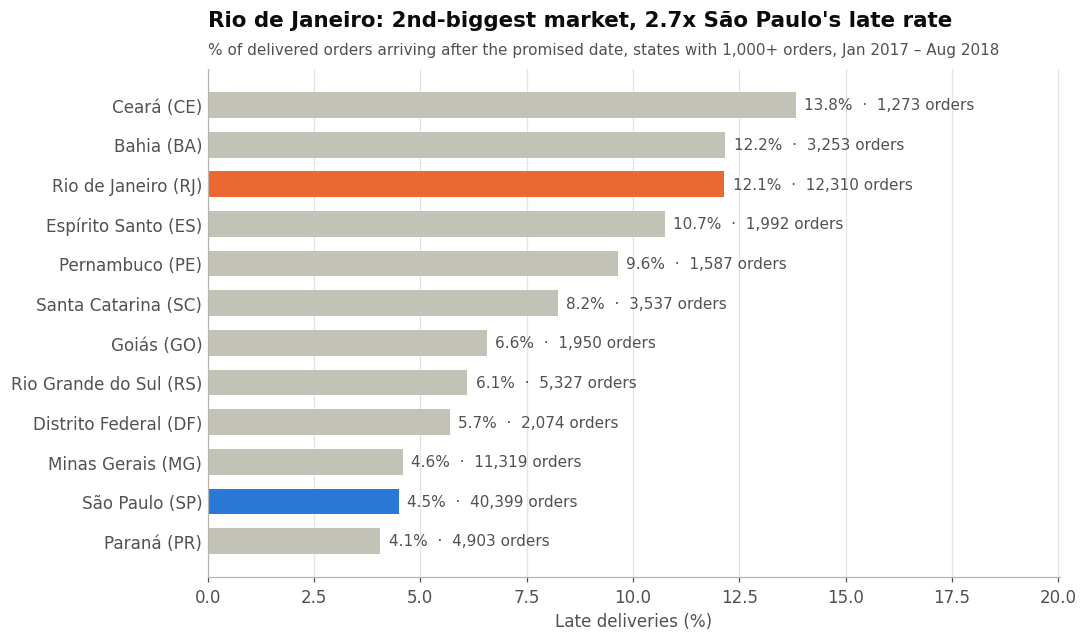

In [8]:
# ---------- Data: late % by state (same query as Day 4, Step 4) ----------
states = pd.read_sql("""
    SELECT c.customer_state AS state,
           COUNT(*) AS orders,
           100.0 * SUM(CASE WHEN date(o.order_delivered_customer_date)
                                 > date(o.order_estimated_delivery_date)
                            THEN 1 ELSE 0 END) / COUNT(*) AS late_pct
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY c.customer_state
""", conn)

NAMES = {"SP": "São Paulo", "RJ": "Rio de Janeiro", "MG": "Minas Gerais", "RS": "Rio Grande do Sul",
         "PR": "Paraná", "SC": "Santa Catarina", "BA": "Bahia", "DF": "Distrito Federal",
         "ES": "Espírito Santo", "GO": "Goiás", "PE": "Pernambuco", "CE": "Ceará"}
NEUTRAL = "#c3c2b7"

# Keep only states with enough orders for a reliable %
big = states[states["orders"] >= 1000].sort_values("late_pct")
labels = big["state"].map(NAMES) + " (" + big["state"] + ")"
colors = [ORANGE if s == "RJ" else (BLUE if s == "SP" else NEUTRAL) for s in big["state"]]

# ---------- Chart 4: highlighted horizontal bars ----------
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(labels, big["late_pct"], color=colors, height=0.65)

for bar, pct, n in zip(bars, big["late_pct"], big["orders"]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f}%  ·  {n:,} orders", va="center", color=INK2, fontsize=10)

ax.set_title("Rio de Janeiro: 2nd-biggest market, 2.7x São Paulo's late rate", pad=28)
ax.text(0, 1.03, "% of delivered orders arriving after the promised date, states with 1,000+ orders, Jan 2017 – Aug 2018",
        transform=ax.transAxes, color=INK2, fontsize=10)
ax.set_xlabel("Late deliveries (%)")
ax.set_xlim(0, big["late_pct"].max() * 1.45)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

fig.savefig("charts/04_late_by_state.png", bbox_inches="tight")
plt.show()

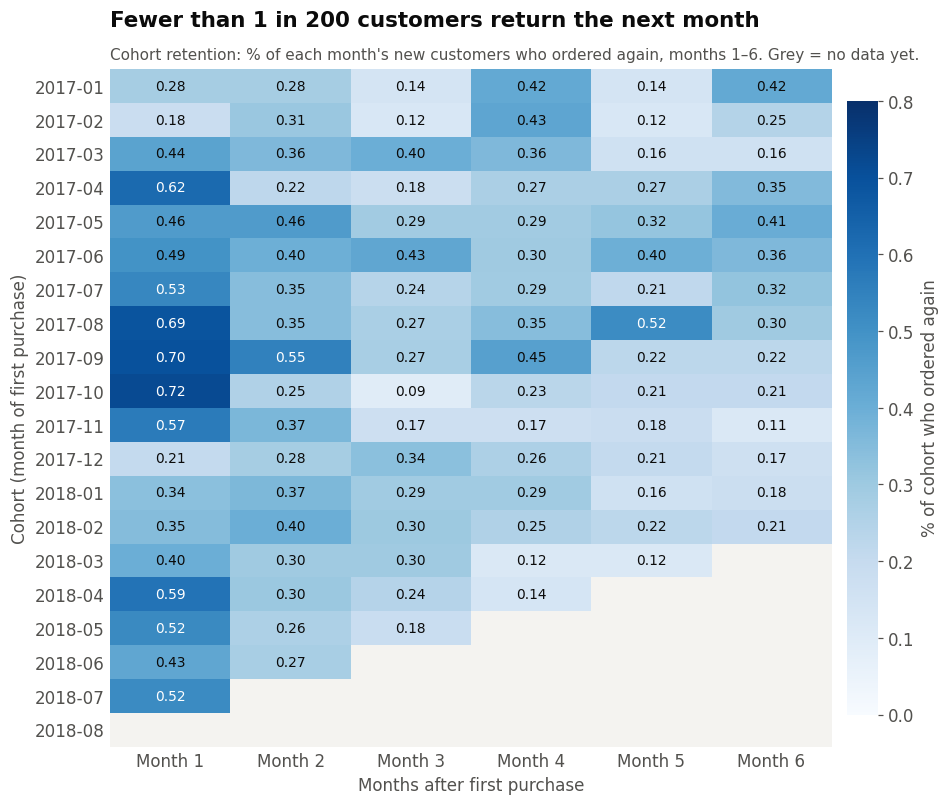

In [9]:
# ---------- Chart 5: cohort retention heatmap (uses `retention` from Day 5) ----------
heat = retention.iloc[:, 1:7]   # months 1-6 (month 0 is always 100%)

fig, ax = plt.subplots(figsize=(9, 8))
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#f4f3f0")          # "no data yet" cells shown in light grey

im = ax.imshow(heat.values, cmap=cmap, vmin=0, vmax=0.8, aspect="auto")

# Write the value inside each cell
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.5 else INK)

ax.set_xticks(range(heat.shape[1]))
ax.set_xticklabels([f"Month {m}" for m in heat.columns])
ax.set_yticks(range(heat.shape[0]))
ax.set_yticklabels(heat.index)
ax.set_xlabel("Months after first purchase")
ax.set_ylabel("Cohort (month of first purchase)")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)

cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("% of cohort who ordered again", color=INK2)
cbar.outline.set_visible(False)

ax.set_title("Fewer than 1 in 200 customers return the next month", pad=28)
ax.text(0, 1.015, "Cohort retention: % of each month's new customers who ordered again, months 1–6. Grey = no data yet.",
        transform=ax.transAxes, color=INK2, fontsize=10)

fig.savefig("charts/05_cohort_retention.png", bbox_inches="tight")
plt.show()